In [ ]:
import pandas as pd

df_weather = pd.read_csv("final_datasets/df_weather_combined_2022_2026.csv")

df_weather.head()

,station_id,date,tavg,tmin,tmax,prcp,wspd,tsun,cloud_cover,pres_dwd,station,source,pres_meteostat
0,NaN,2022-01-01,11.2,9.5,11.7,1.7,16.4,NaN,NaN,NaN,Alexanderplatz,Meteostat,1021.3
1,NaN,2022-01-02,9.5,8.1,10.9,2.0,17.7,NaN,NaN,NaN,Alexanderplatz,Meteostat,1013.0
2,NaN,2022-01-03,8.7,7.0,10.0,4.0,20.2,NaN,NaN,NaN,Alexanderplatz,Meteostat,1006.5
3,NaN,2022-01-04,6.8,5.4,7.7,3.0,12.1,NaN,NaN,NaN,Alexanderplatz,Meteostat,996.8
4,NaN,2022-01-05,3.7,3.0,4.9,2.3,18.8,NaN,NaN,NaN,Alexanderplatz,Meteostat,997.8


In [3]:
# Check dataset dimensions
print("Dataset shape:", df_weather.shape)

# Check column names and data types
print("\nData types:")
print(df_weather.dtypes)

# Check date range
df_weather["date"] = pd.to_datetime(df_weather["date"])

print("\nDate range:")
print("Start:", df_weather["date"].min())
print("End:", df_weather["date"].max())

# Check number of stations and sources
print("\nStations:")
print(df_weather["station"].nunique())
print(df_weather["station"].unique())

print("\nSources:")
print(df_weather["source"].value_counts())

# Check missing values
print("\nMissing values:")
print(df_weather.isna().sum())

Dataset shape: (14822, 13)

Data types:
station_id        float64
date                  str
tavg              float64
tmin              float64
tmax              float64
prcp              float64
wspd              float64
tsun              float64
cloud_cover       float64
pres_dwd          float64
station               str
source                str
pres_meteostat    float64
dtype: object

Date range:
Start: 2022-01-01 00:00:00
End: 2026-10-30 00:00:00

Stations:
7
<ArrowStringArray>
[    'Alexanderplatz', 'Berlin Brandenburg',               'Buch',
             'Dahlem',            'Marzahn',              'Tegel',
          'Tempelhof']
Length: 7, dtype: str

Sources:
source
DWD          8193
Meteostat    6629
Name: count, dtype: int64

Missing values:
station_id        12072
date                  0
tavg                 40
tmin                 43
tmax                 43
prcp               1599
wspd               4762
tsun              12330
cloud_cover       13192
pres_dwd          13

In [4]:
# Extract year from the date
df_weather["year"] = df_weather["date"].dt.year

# Expected calendar days per year
expected_days = {
    2022: 365,
    2023: 365,
    2024: 366,
    2025: 365,
    2026: 303  # 1 January to 30 October
}

# Summarise temperature coverage by station, source and year
weather_coverage = (
    df_weather
    .groupby(["station", "source", "year"])
    .agg(
        rows=("date", "size"),
        unique_dates=("date", "nunique"),
        tavg_available=("tavg", "count"),
        tmax_available=("tmax", "count")
    )
    .reset_index()
)

# Calculate Tmax coverage against expected calendar days
weather_coverage["expected_days"] = (
    weather_coverage["year"].map(expected_days)
)

weather_coverage["tmax_coverage_pct"] = (
    weather_coverage["tmax_available"]
    / weather_coverage["expected_days"] * 100
).round(1)

# Display results
weather_coverage.sort_values(
    ["station", "source", "year"]
).reset_index(drop=True)

,station,source,year,rows,unique_dates,tavg_available,tmax_available,expected_days,tmax_coverage_pct
0,Alexanderplatz,Meteostat,2022,365,365,353,353,365,96.7
1,Alexanderplatz,Meteostat,2023,365,365,365,365,365,100.0
2,Alexanderplatz,Meteostat,2024,366,366,366,366,366,100.0
3,Alexanderplatz,Meteostat,2025,365,365,365,365,365,100.0
4,Alexanderplatz,Meteostat,2026,303,303,303,303,303,100.0
5,Berlin Brandenburg,DWD,2022,365,365,365,365,365,100.0
6,Berlin Brandenburg,DWD,2023,365,365,365,365,365,100.0
7,Berlin Brandenburg,DWD,2024,366,366,366,366,366,100.0
8,Berlin Brandenburg,DWD,2025,365,365,365,365,365,100.0
9,Berlin Brandenburg,DWD,2026,283,283,283,283,303,93.4


In [7]:
# Compare DWD and Meteostat where both have data
overlap = df_weather.pivot_table(
    index=["station", "date"],
    columns="source",
    values=["tavg", "tmax"],
    aggfunc="first"
)

# Keep dates with both sources available for both variables
overlap = overlap.dropna(
    subset=[
        ("tavg", "DWD"),
        ("tavg", "Meteostat"),
        ("tmax", "DWD"),
        ("tmax", "Meteostat")
    ]
)

# Create a DataFrame with flat column names
comparison = pd.DataFrame({
    "station": overlap.index.get_level_values("station"),
    "tavg_abs_diff": (
        overlap[("tavg", "DWD")] -
        overlap[("tavg", "Meteostat")]
    ).abs().values,
    "tmax_abs_diff": (
        overlap[("tmax", "DWD")] -
        overlap[("tmax", "Meteostat")]
    ).abs().values
})

# Summarise differences by station
source_comparison = (
    comparison
    .groupby("station")
    .agg(
        overlapping_dates=("tmax_abs_diff", "count"),
        mean_tavg_difference=("tavg_abs_diff", "mean"),
        mean_tmax_difference=("tmax_abs_diff", "mean"),
        max_tmax_difference=("tmax_abs_diff", "max")
    )
    .round(2)
)

source_comparison

,overlapping_dates,mean_tavg_difference,mean_tmax_difference,max_tmax_difference
station,,,,
Dahlem,1379,0.0,0.0,0.0
Marzahn,866,0.0,0.0,0.0
Tempelhof,282,0.0,0.0,0.0


In [8]:
# Create a table with one row per station and date
tmax_sources = df_weather.pivot_table(
    index=["station", "date"],
    columns="source",
    values="tmax",
    aggfunc="first"
)

# Prioritise DWD and use Meteostat as fallback
weather_tmax = pd.DataFrame(index=tmax_sources.index)

weather_tmax["tmax"] = (
    tmax_sources["DWD"].combine_first(tmax_sources["Meteostat"])
)

# Record which source supplied the selected value
weather_tmax["tmax_source"] = "Missing"

weather_tmax.loc[
    tmax_sources["DWD"].notna(),
    "tmax_source"
] = "DWD"

weather_tmax.loc[
    tmax_sources["DWD"].isna() &
    tmax_sources["Meteostat"].notna(),
    "tmax_source"
] = "Meteostat"

# Reset index
weather_tmax = weather_tmax.reset_index()

# Check the resulting dataset
print("Shape:", weather_tmax.shape)
print("\nMissing Tmax values:", weather_tmax["tmax"].isna().sum())

print("\nSelected source counts:")
print(weather_tmax["tmax_source"].value_counts())

print("\nDate coverage by station:")
print(
    weather_tmax.groupby("station")["date"]
    .agg(["min", "max", "count"])
)

Shape: (12252, 4)

Missing Tmax values: 0

Selected source counts:
tmax_source
DWD          8183
Meteostat    4069
Name: count, dtype: int64

Date coverage by station:
                          min        max  count
station                                        
Alexanderplatz     2022-01-01 2026-10-30   1752
Berlin Brandenburg 2022-01-01 2026-10-10   1744
Buch               2022-01-01 2026-10-10   1744
Dahlem             2022-01-01 2026-10-30   1748
Marzahn            2022-01-01 2026-10-22   1736
Tegel              2022-01-01 2026-10-30   1764
Tempelhof          2022-01-01 2026-10-30   1764


In [9]:
# Define the full analysis date range
full_date_range = pd.date_range(
    start="2022-01-01",
    end="2026-10-30",
    freq="D"
)

# Check missing dates for each station
coverage_check = []

for station in weather_tmax["station"].unique():

    # Dates available for this station
    available_dates = pd.DatetimeIndex(
        weather_tmax.loc[
            weather_tmax["station"] == station, "date"
        ]
    )

    # Find dates without a Tmax observation
    missing_dates = full_date_range.difference(available_dates)

    coverage_check.append({
        "station": station,
        "available_days": len(available_dates),
        "missing_days": len(missing_dates),
        "first_missing_date": (
            missing_dates.min() if len(missing_dates) > 0 else None
        ),
        "last_missing_date": (
            missing_dates.max() if len(missing_dates) > 0 else None
        )
    })

coverage_check = pd.DataFrame(coverage_check)

coverage_check

,station,available_days,missing_days,first_missing_date,last_missing_date
0,Alexanderplatz,1752,12,2022-06-02,2022-06-13
1,Berlin Brandenburg,1744,20,2026-10-11,2026-10-30
2,Buch,1744,20,2026-10-11,2026-10-30
3,Dahlem,1748,16,2025-03-03,2025-03-18
4,Marzahn,1736,28,2024-08-27,2026-10-30
5,Tegel,1764,0,NaT,NaT
6,Tempelhof,1764,0,NaT,NaT


In [10]:
# Filter the summer period: June to September
summer_weather = weather_tmax[
    weather_tmax["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Calculate expected summer days for each year
summer_expected = {
    2022: 122,
    2023: 122,
    2024: 122,
    2025: 122,
    2026: 122
}

# Count available summer observations
summer_coverage = (
    summer_weather
    .groupby([
        "station",
        summer_weather["date"].dt.year.rename("year")
    ])
    .agg(
        available_days=("date", "nunique")
    )
    .reset_index()
)

# Add expected days and calculate coverage
summer_coverage["expected_days"] = (
    summer_coverage["year"].map(summer_expected)
)

summer_coverage["missing_days"] = (
    summer_coverage["expected_days"]
    - summer_coverage["available_days"]
)

summer_coverage["coverage_pct"] = (
    summer_coverage["available_days"]
    / summer_coverage["expected_days"] * 100
).round(1)

summer_coverage.sort_values(
    ["station", "year"]
).reset_index(drop=True)

,station,year,available_days,expected_days,missing_days,coverage_pct
0,Alexanderplatz,2022,110,122,12,90.2
1,Alexanderplatz,2023,122,122,0,100.0
2,Alexanderplatz,2024,122,122,0,100.0
3,Alexanderplatz,2025,122,122,0,100.0
4,Alexanderplatz,2026,122,122,0,100.0
5,Berlin Brandenburg,2022,122,122,0,100.0
6,Berlin Brandenburg,2023,122,122,0,100.0
7,Berlin Brandenburg,2024,122,122,0,100.0
8,Berlin Brandenburg,2025,122,122,0,100.0
9,Berlin Brandenburg,2026,122,122,0,100.0


In [11]:
# Define the heat indicator calculation
def calculate_heat_indicators(group):

    # Sort observations chronologically
    group = group.sort_values("date").set_index("date")

    # Reindex to include all 122 summer calendar days
    full_dates = pd.date_range(
        start=f"{group.index.year[0]}-06-01",
        end=f"{group.index.year[0]}-09-30",
        freq="D"
    )

    daily_tmax = group["tmax"].reindex(full_dates)

    # Identify hot and extreme-hot days
    hot_days = daily_tmax >= 30
    extreme_hot_days = daily_tmax >= 35

    # Missing observations break consecutive hot-day runs
    hot_days = hot_days.fillna(False)

    # Calculate consecutive hot-day runs
    run_groups = (~hot_days).cumsum()
    longest_hot_spell = (
        hot_days.groupby(run_groups).sum().max()
    )

    return pd.Series({
        "available_days": daily_tmax.notna().sum(),
        "mean_summer_tmax": daily_tmax.mean(),
        "hot_days_30C": hot_days.sum(),
        "extreme_hot_days_35C": extreme_hot_days.sum(),
        "hot_day_pct": (
            hot_days.sum() / daily_tmax.notna().sum() * 100
        ),
        "longest_hot_spell": longest_hot_spell
    })


# Calculate indicators for every station and summer
summer_kpis = (
    summer_weather
    .groupby([
        "station",
        summer_weather["date"].dt.year.rename("year")
    ])
    .apply(calculate_heat_indicators)
    .reset_index()
)

# Round numerical results
summer_kpis = summer_kpis.round(2)

summer_kpis

,station,year,available_days,mean_summer_tmax,hot_days_30C,extreme_hot_days_35C,hot_day_pct,longest_hot_spell
0,Alexanderplatz,2022,110.0,23.31,13.0,2.0,11.82,2.0
1,Alexanderplatz,2023,122.0,23.82,4.0,0.0,3.28,2.0
2,Alexanderplatz,2024,122.0,23.47,11.0,0.0,9.02,2.0
3,Alexanderplatz,2025,122.0,22.44,6.0,1.0,4.92,3.0
4,Alexanderplatz,2026,122.0,23.42,13.0,3.0,10.66,5.0
5,Berlin Brandenburg,2022,122.0,25.05,21.0,6.0,17.21,5.0
6,Berlin Brandenburg,2023,122.0,25.27,13.0,1.0,10.66,4.0
7,Berlin Brandenburg,2024,122.0,24.97,21.0,0.0,17.21,6.0
8,Berlin Brandenburg,2025,122.0,23.94,11.0,1.0,9.02,3.0
9,Berlin Brandenburg,2026,122.0,25.10,18.0,5.0,14.75,5.0


In [12]:
# Calculate the daily average Tmax across available stations
berlin_daily_weather = (
    summer_weather
    .groupby("date")
    .agg(
        mean_station_tmax=("tmax", "mean"),
        stations_available=("station", "nunique"),
        min_station_tmax=("tmax", "min"),
        max_station_tmax=("tmax", "max")
    )
    .reset_index()
)

# Extract year
berlin_daily_weather["year"] = (
    berlin_daily_weather["date"].dt.year
)

# Check the resulting daily dataset
print("Shape:", berlin_daily_weather.shape)

print("\nStation availability per day:")
print(
    berlin_daily_weather["stations_available"]
    .value_counts()
    .sort_index()
)

print("\nDaily average Tmax summary:")
print(
    berlin_daily_weather["mean_station_tmax"]
    .describe()
)

berlin_daily_weather.head()

Shape: (610, 6)

Station availability per day:
stations_available
6     21
7    589
Name: count, dtype: int64

Daily average Tmax summary:
count    610.000000
mean      24.319227
std        4.570024
min       12.257143
25%       21.053571
50%       24.142857
75%       27.410714
max       39.228571
Name: mean_station_tmax, dtype: float64


,date,mean_station_tmax,stations_available,min_station_tmax,max_station_tmax,year
0,2022-06-01,19.614286,7,18.1,20.5,2022
1,2022-06-02,19.633333,6,17.9,20.4,2022
2,2022-06-03,25.250000,6,23.0,26.1,2022
3,2022-06-04,24.333333,6,23.3,25.0,2022
4,2022-06-05,28.033333,6,26.5,28.7,2022


In [13]:
# Define hot and extreme-hot days
berlin_daily_weather["hot_day"] = (
    berlin_daily_weather["mean_station_tmax"] >= 30
)

berlin_daily_weather["extreme_hot_day"] = (
    berlin_daily_weather["mean_station_tmax"] >= 35
)

# Calculate annual summer indicators
annual_heat_summary = (
    berlin_daily_weather
    .groupby("year")
    .agg(
        summer_days=("date", "nunique"),
        mean_summer_tmax=("mean_station_tmax", "mean"),
        max_daily_tmax=("mean_station_tmax", "max"),
        hot_days_30C=("hot_day", "sum"),
        extreme_hot_days_35C=("extreme_hot_day", "sum"),
        hot_day_pct=("hot_day", lambda x: x.mean() * 100)
    )
    .round(2)
    .reset_index()
)

annual_heat_summary

,year,summer_days,mean_summer_tmax,max_daily_tmax,hot_days_30C,extreme_hot_days_35C,hot_day_pct
0,2022,122,24.49,37.71,16,5,13.11
1,2023,122,24.70,34.26,9,0,7.38
2,2024,122,24.38,33.60,13,0,10.66
3,2025,122,23.51,37.40,9,1,7.38
4,2026,122,24.51,39.23,17,4,13.93


- 2026: 17 hot days (13.93% of summer days) and 4 extreme-hot days. Its maximum daily station average was 39.23°C.
- 2022: Almost as many hot days (16), and 5 extreme-hot days — the highest count in this period.
- 2023 and 2025: Both had 9 hot days (7.38%), the lowest counts.
- Mean summer Tmax: Ranged from 23.51°C in 2025 to 24.70°C in 2023. The differences in seasonal averages are relatively modest compared with the differences in hot-day counts.

In [14]:
# Calculate the longest consecutive hot spell for each summer
def longest_hot_spell(group):
    group = group.sort_values("date")

    # A new group starts whenever a day is not hot
    run_groups = (~group["hot_day"]).cumsum()

    # Count consecutive hot days within each run
    hot_runs = group[group["hot_day"]].groupby(run_groups).size()

    return hot_runs.max() if not hot_runs.empty else 0


longest_spells = (
    berlin_daily_weather
    .groupby("year")
    .apply(longest_hot_spell)
    .rename("longest_hot_spell")
    .reset_index()
)

longest_spells

,year,longest_hot_spell
0,2022,5
1,2023,3
2,2024,2
3,2025,3
4,2026,5


- 2026 recorded the most hot days: 17, compared with 9 in both 2023 and 2025.
- 2022 and 2026 had the longest hot spells: five consecutive days each.
- 2022 had the most extreme-hot days: five, compared with four in 2026.
- 2025 had the lowest mean summer Tmax: 23.51°C.
- 2023 and 2024 had no extreme-hot days according to our station-average threshold of 35°C.

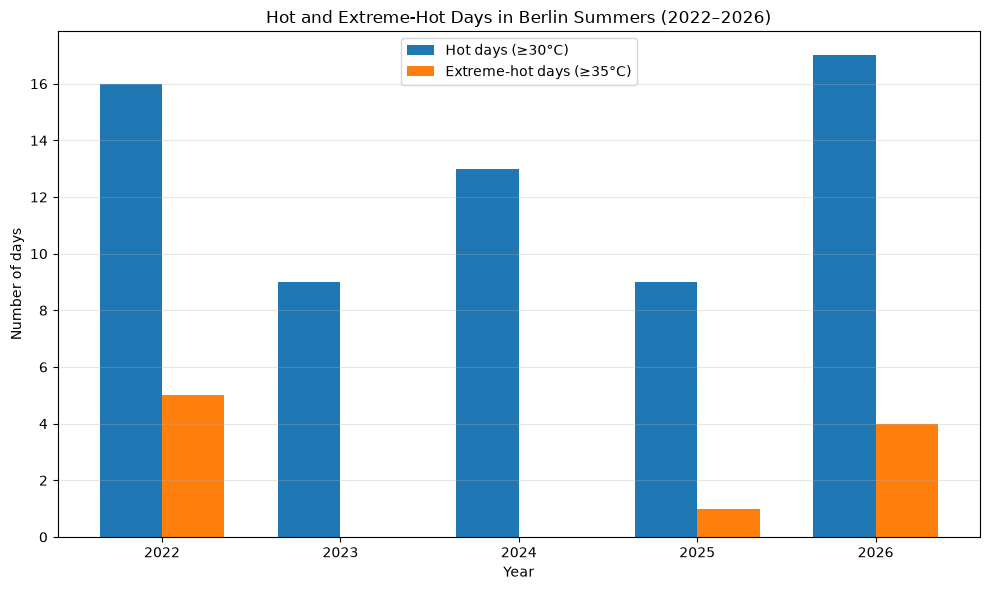

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Compare hot and extreme-hot days by year
plt.figure(figsize=(10, 6))

x = np.arange(len(annual_heat_summary))
width = 0.35

plt.bar(
    x - width / 2,
    annual_heat_summary["hot_days_30C"],
    width,
    label="Hot days (≥30°C)"
)

plt.bar(
    x + width / 2,
    annual_heat_summary["extreme_hot_days_35C"],
    width,
    label="Extreme-hot days (≥35°C)"
)

plt.title("Hot and Extreme-Hot Days in Berlin Summers (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.xticks(x, annual_heat_summary["year"])
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Berlin experienced substantial year-to-year variability in summer heat between 2022 and 2026. The summers of 2022 and 2026 recorded the highest numbers of hot and extreme-hot days, while 2023 and 2025 had fewer hot days.

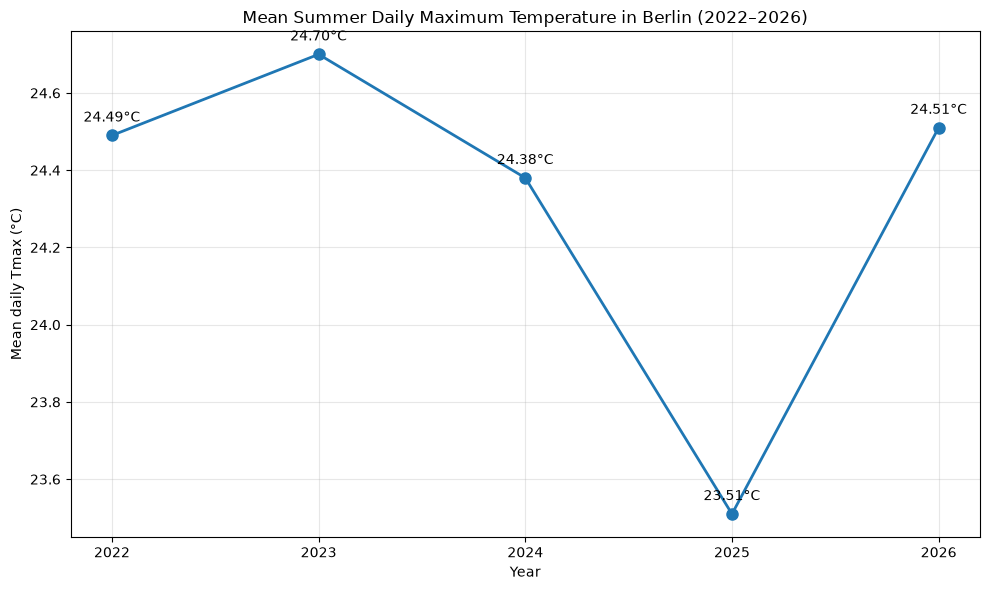

In [20]:
# Plot mean summer Tmax by year
plt.figure(figsize=(10, 6))

plt.plot(
    annual_heat_summary["year"],
    annual_heat_summary["mean_summer_tmax"],
    marker="o",
    linewidth=2,
    markersize=8
)

# Add temperature labels above each point
for x, y in zip(
    annual_heat_summary["year"],
    annual_heat_summary["mean_summer_tmax"]
):
    plt.annotate(
        f"{y:.2f}°C",
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.title("Mean Summer Daily Maximum Temperature in Berlin (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Mean daily Tmax (°C)")
plt.xticks(annual_heat_summary["year"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Mean summer maximum temperatures fluctuated between 23.51°C and 24.70°C from 2022 to 2026. After reaching the lowest value in 2025, the average increased noticeably in 2026.

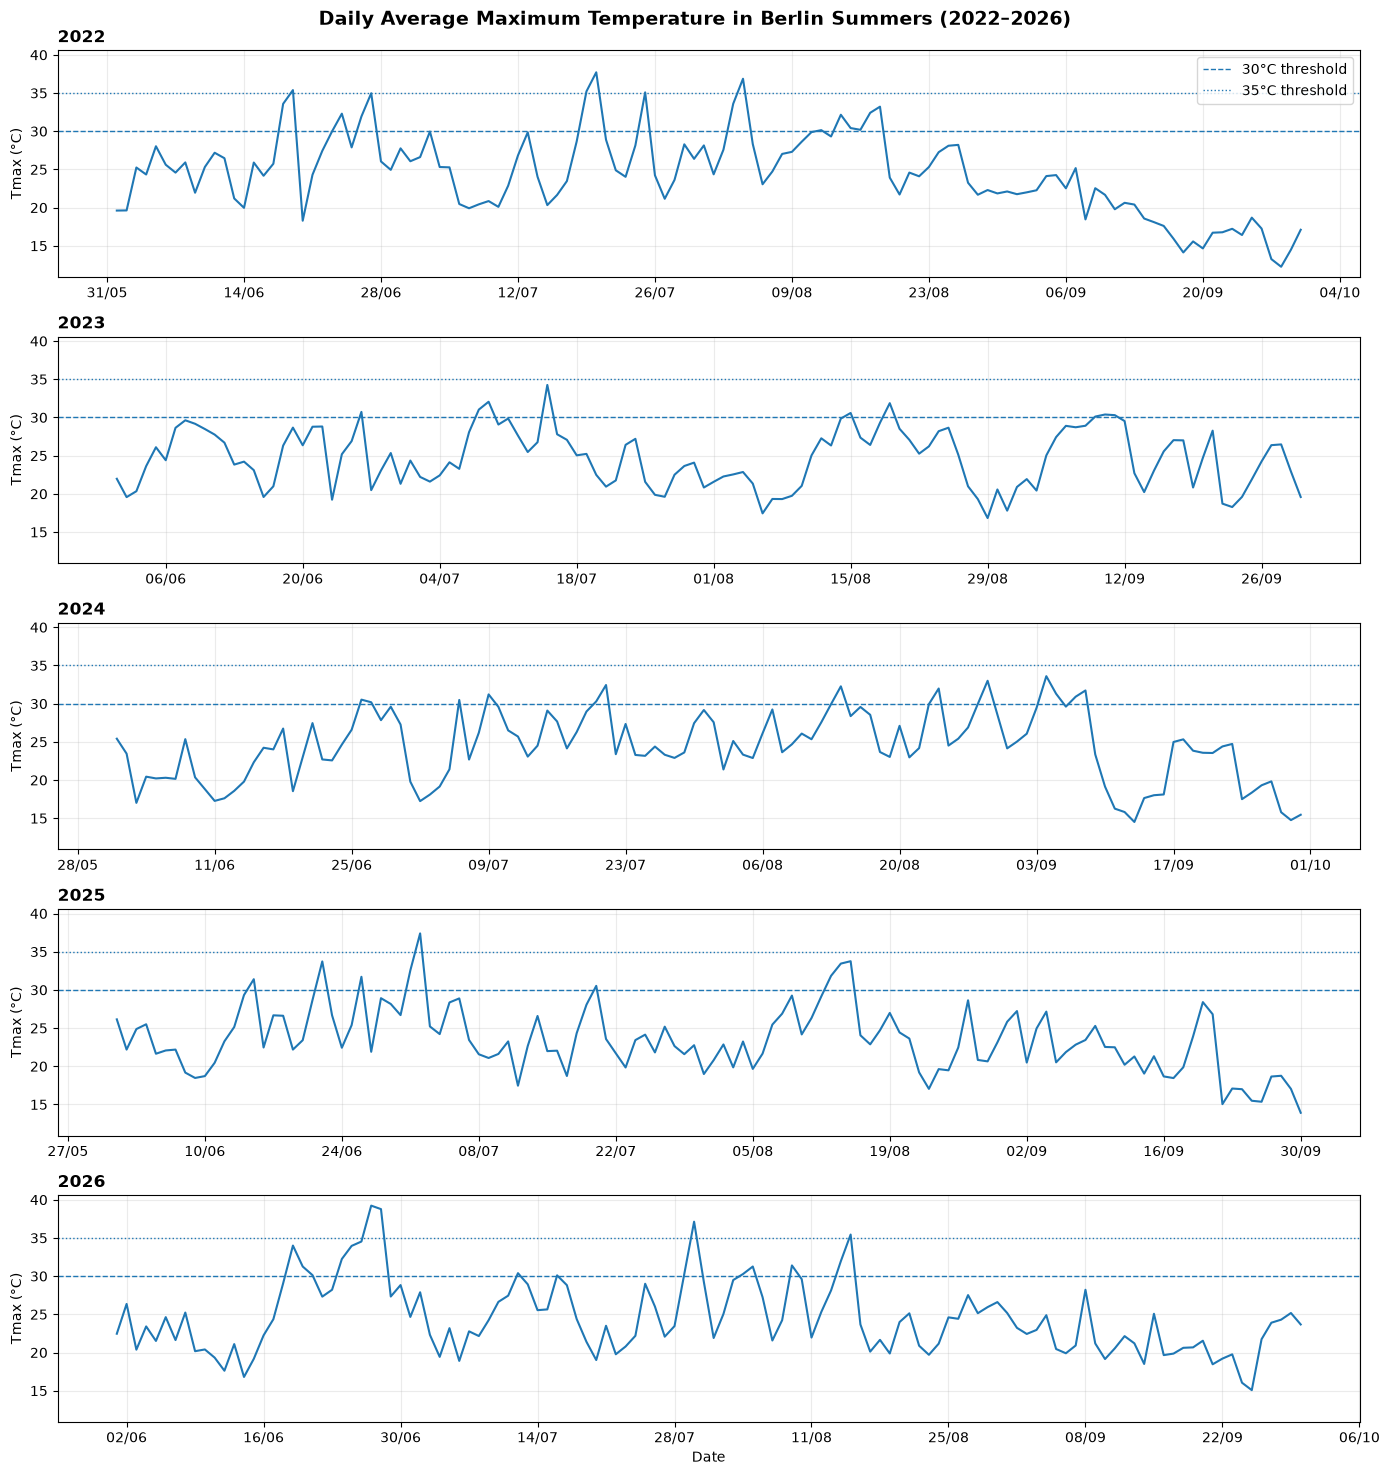

In [22]:
import matplotlib.dates as mdates

# Create one temperature timeline per year
fig, axes = plt.subplots(
    5, 1,
    figsize=(14, 15),
    sharey=True
)

for ax, year in zip(axes, sorted(berlin_daily_weather["year"].unique())):

    yearly_data = berlin_daily_weather[
        berlin_daily_weather["year"] == year
    ].sort_values("date")

    # Plot daily station-average maximum temperature
    ax.plot(
        yearly_data["date"],
        yearly_data["mean_station_tmax"],
        linewidth=1.5
    )

    # Add heat threshold reference lines
    ax.axhline(30, linestyle="--", linewidth=1, label="30°C threshold")
    ax.axhline(35, linestyle=":", linewidth=1, label="35°C threshold")

    ax.set_title(str(year), loc="left", fontweight="bold")
    ax.set_ylabel("Tmax (°C)")
    ax.grid(alpha=0.25)

    # Format dates as day/month
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))

    # Show legend only in the first panel
    if year == 2022:
        ax.legend(loc="upper right")

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Daily Average Maximum Temperature in Berlin Summers (2022–2026)",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

1. Most pronounced heat peaks
- 2022 and 2026 had the most pronounced extreme-temperature peaks.
- 2022 had several pronounced peaks across June, July and August.
- 2026 recorded the highest daily station-average Tmax in the dataset, at approximately 39.23°C, in late June.
2. Different patterns despite similar seasonal averages
- 2023: Relatively sustained warm periods, particularly during July and August, despite having only nine hot days.
- 2024: Several temperature fluctuations, with daily station averages reaching 33.60°C but never crossing the 35°C threshold.
- 2025: A pronounced early-July peak, followed by generally cooler conditions later in the summer.
- 2026: A particularly pronounced late-June peak, alongside the highest number of hot days.
3. September cooling
- All five summers show a general decline in daily maximum temperatures during September.
- The timing and magnitude of this cooling vary between years.

In [ ]:
# Prepare summer data to check the hottest recorded day by station
summer_station_tmax = weather_tmax[
    weather_tmax["date"].dt.month.isin([6, 7, 8, 9])
].copy()

# Extract year
summer_station_tmax["year"] = (
    summer_station_tmax["date"].dt.year
)

# Find the hottest recorded day for each station and year
hottest_days = (
    summer_station_tmax
    .loc[
        summer_station_tmax.groupby(
            ["station", "year"]
        )["tmax"].idxmax()
    ]
    [["station", "year", "date", "tmax", "tmax_source"]]
    .sort_values(["station", "year"])
    .reset_index(drop=True)
)

hottest_days

,station,year,date,tmax,tmax_source
0,Alexanderplatz,2022,2022-07-20,37.3,Meteostat
1,Alexanderplatz,2023,2023-07-15,32.7,Meteostat
2,Alexanderplatz,2024,2024-09-04,32.8,Meteostat
3,Alexanderplatz,2025,2025-07-02,36.8,Meteostat
4,Alexanderplatz,2026,2026-06-27,38.5,Meteostat
5,Berlin Brandenburg,2022,2022-07-20,38.1,DWD
6,Berlin Brandenburg,2023,2023-07-15,35.4,DWD
7,Berlin Brandenburg,2024,2024-08-29,34.3,DWD
8,Berlin Brandenburg,2025,2025-07-02,37.5,DWD
9,Berlin Brandenburg,2026,2026-06-28,40.3,DWD


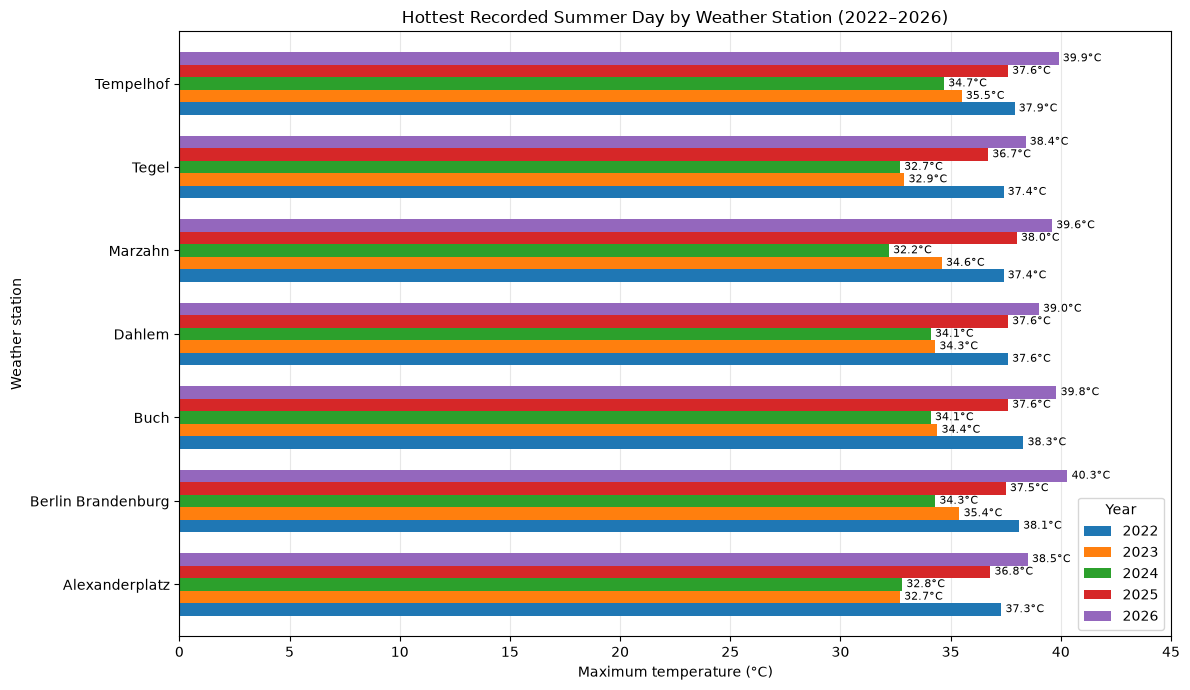

In [24]:
# Arrange the data for plotting
plot_data = hottest_days.pivot(
    index="station",
    columns="year",
    values="tmax"
)

# Create the grouped horizontal bar chart
ax = plot_data.plot(
    kind="barh",
    figsize=(12, 7),
    width=0.75
)

# Add temperature labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f°C",
        padding=3,
        fontsize=8
    )

# Format the chart
ax.set_title(
    "Hottest Recorded Summer Day by Weather Station (2022–2026)"
)
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Weather station")
ax.set_xlim(0, 45)
ax.legend(title="Year")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

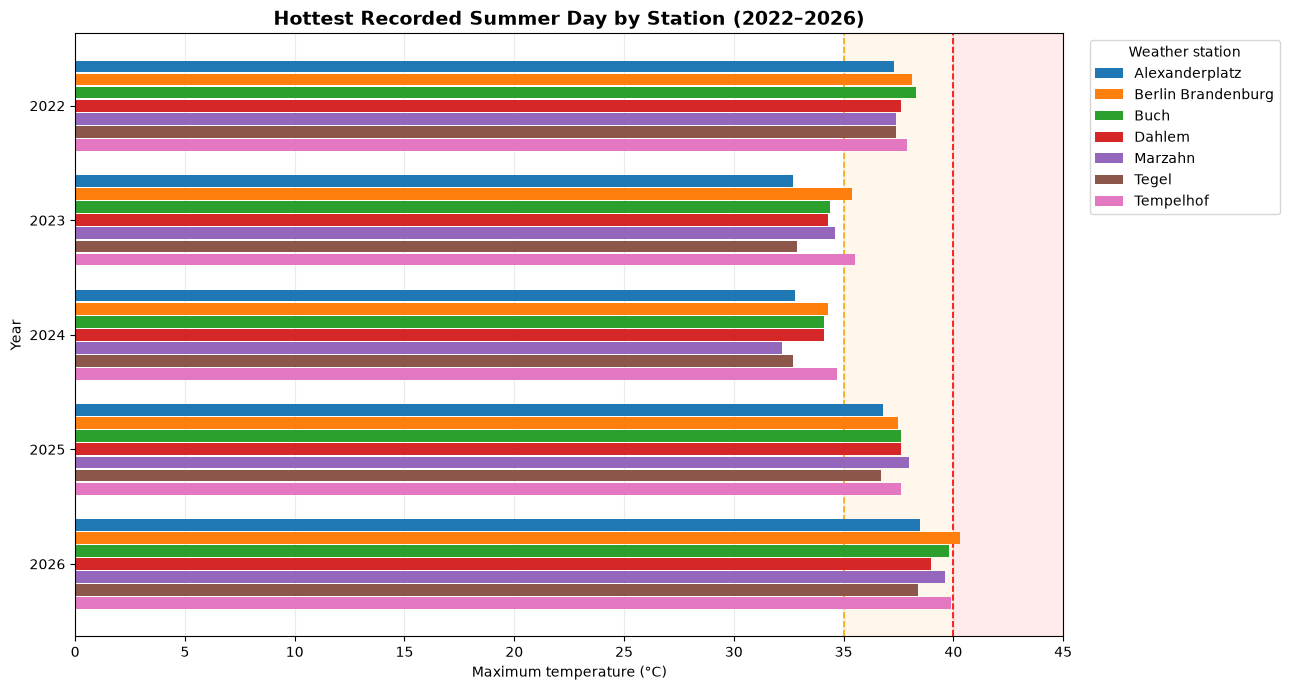

In [25]:
# Arrange data with years as rows and stations as columns
plot_data = hottest_days.pivot(
    index="year",
    columns="station",
    values="tmax"
).sort_index()

# Define bar positions
years = plot_data.index
stations = plot_data.columns

n_stations = len(stations)
bar_height = 0.8 / n_stations

# Create figure
fig, ax = plt.subplots(figsize=(13, 7))

# Add shaded temperature zones
ax.axvspan(35, 40, color="orange", alpha=0.08, zorder=0)
ax.axvspan(40, 45, color="red", alpha=0.08, zorder=0)

# Add temperature reference lines
ax.axvline(
    35, color="orange", linestyle="--",
    linewidth=1.2, label="_nolegend_"
)
ax.axvline(
    40, color="red", linestyle="--",
    linewidth=1.2, label="_nolegend_"
)

# Plot grouped horizontal bars
for i, station in enumerate(stations):

    offset = (
        i - (n_stations - 1) / 2
    ) * bar_height

    ax.barh(
        years + offset,
        plot_data[station],
        height=bar_height * 0.9,
        label=station,
        zorder=2
    )

# Format chart
ax.set_title(
    "Hottest Recorded Summer Day by Station (2022–2026)",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Maximum temperature (°C)")
ax.set_ylabel("Year")
ax.set_yticks(years)
ax.set_yticklabels(years)
ax.set_xlim(0, 45)

# Put earliest year at the top
ax.invert_yaxis()

ax.legend(
    title="Weather station",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

1. 2026 — Highest recorded temperatures
- All seven stations recorded summer maximum temperatures above 38°C.
- Berlin Brandenburg recorded the dataset's highest value: 40.3°C on 28 June 2026.
- Tempelhof followed with 39.9°C, while Buch recorded 39.8°C.
2. 2022 — Widespread high temperatures
- All seven stations recorded maximum temperatures above 35°C.
- Values ranged from 37.3°C to 38.3°C.
- This was also the year with the highest number of extreme-hot days based on the daily station average (5).
3. 2023 and 2024 — Lower peak temperatures
- In 2023, only Berlin Brandenburg (35.4°C) and Tempelhof (35.5°C) exceeded 35°C.
- In 2024, none of the seven stations exceeded 35°C. The highest value was 34.7°C at Tempelhof.
4. Differences between stations
- Berlin Brandenburg and Tempelhof frequently recorded among the highest station maxima.
- However, Buch had the highest value in 2022, and Marzahn in 2025.
- Tegel was generally among the stations with lower recorded maxima.

In [26]:
# Arrange minimum temperatures by station, date and source
tmin_sources = df_weather.pivot_table(
    index=["station", "date"],
    columns="source",
    values="tmin",
    aggfunc="first"
)

# Prioritise DWD and use Meteostat as fallback
weather_tmin = pd.DataFrame(index=tmin_sources.index)

weather_tmin["tmin"] = tmin_sources["DWD"].combine_first(
    tmin_sources["Meteostat"]
)

weather_tmin["tmin_source"] = "Missing"

weather_tmin.loc[
    tmin_sources["DWD"].notna(), "tmin_source"
] = "DWD"

weather_tmin.loc[
    tmin_sources["DWD"].isna() & tmin_sources["Meteostat"].notna(),
    "tmin_source"
] = "Meteostat"

weather_tmin = weather_tmin.reset_index()

# Keep June to September
summer_tmin = weather_tmin[
    weather_tmin["date"].dt.month.isin([6, 7, 8, 9])
].copy()

summer_tmin["year"] = summer_tmin["date"].dt.year

# Identify tropical nights
summer_tmin["tropical_night"] = summer_tmin["tmin"] >= 20

# Calculate annual tropical-night indicators per station
tropical_nights_summary = (
    summer_tmin
    .groupby(["station", "year"])
    .agg(
        available_nights=("tmin", "count"),
        tropical_nights=("tropical_night", "sum")
    )
    .reset_index()
)

tropical_nights_summary

,station,year,available_nights,tropical_nights
0,Alexanderplatz,2022,110,2
1,Alexanderplatz,2023,122,0
2,Alexanderplatz,2024,122,2
3,Alexanderplatz,2025,122,0
4,Alexanderplatz,2026,122,5
5,Berlin Brandenburg,2022,122,0
6,Berlin Brandenburg,2023,122,1
7,Berlin Brandenburg,2024,122,0
8,Berlin Brandenburg,2025,122,0
9,Berlin Brandenburg,2026,122,1


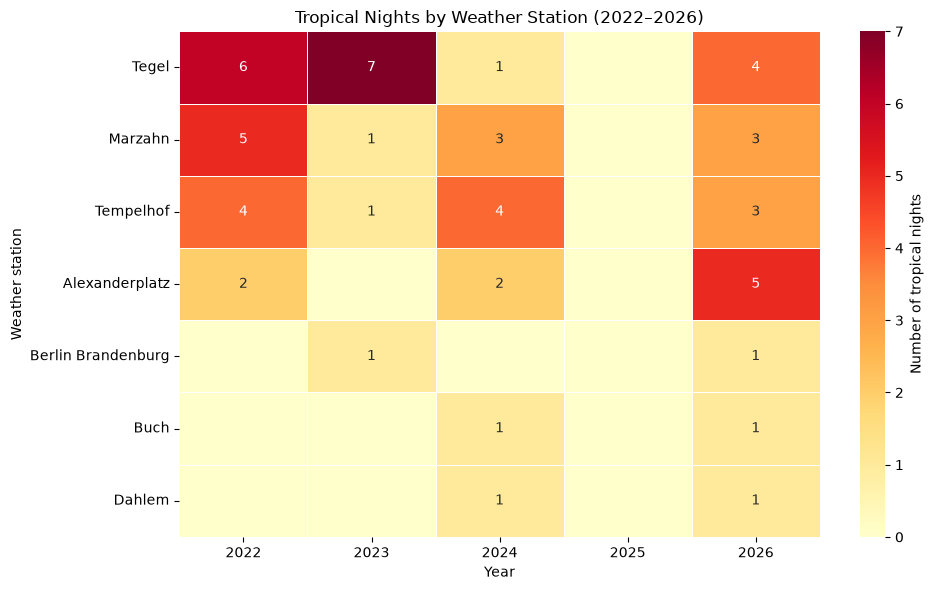

In [29]:
import seaborn as sns

# Sort stations by total tropical nights
tropical_heatmap = (
    tropical_nights_summary
    .pivot(
        index="station",
        columns="year",
        values="tropical_nights"
    )
)

station_order = (
    tropical_heatmap
    .sum(axis=1)
    .sort_values(ascending=False)
    .index
)

tropical_heatmap = tropical_heatmap.loc[station_order]

# Hide annotations for zero values
annotations = tropical_heatmap.astype(str)
annotations = annotations.mask(tropical_heatmap == 0, "")

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    tropical_heatmap,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=7,
    linewidths=0.5,
    cbar_kws={"label": "Number of tropical nights"}
)

plt.title("Tropical Nights by Weather Station (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Weather station")
plt.tight_layout()
plt.show()

Counts represent station-level nights with daily minimum temperature ≥20°C. The same calendar night may be counted at multiple stations.

Tropical nights varied considerably between weather stations and summers. Tegel recorded the highest cumulative number (18) between 2022 and 2026, while Alexanderplatz showed its highest count in 2026 (5). No tropical nights were recorded at any of the seven stations in summer 2025. These differences highlight spatial and year-to-year variation in nighttime temperature, although station measurements cannot be interpreted as neighbourhood-wide exposure.

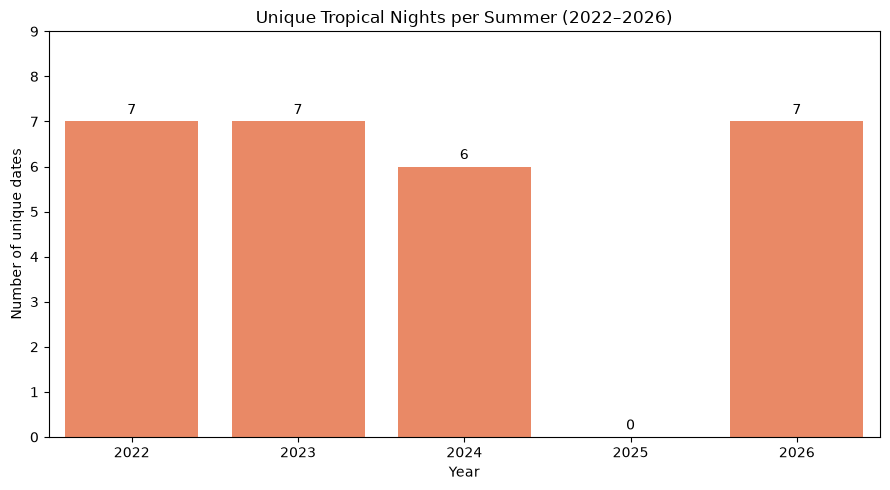

In [38]:
# Include all years, including years with zero tropical nights
annual_unique_nights = (
    unique_tropical_dates
    .set_index("year")["unique_nights"]
    .reindex(range(2022, 2027), fill_value=0)
    .reset_index()
)

annual_unique_nights.columns = ["year", "unique_nights"]

# Plot
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=annual_unique_nights,
    x="year",
    y="unique_nights",
    color="coral"
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Unique Tropical Nights per Summer (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Number of unique dates")
plt.ylim(0, annual_unique_nights["unique_nights"].max() + 2)
plt.tight_layout()
plt.show()

- 2022, 2023 and 2026: Each recorded 7 unique dates with at least one station registering a tropical night.
- 2024: Recorded 6 unique dates.
- 2025: No station recorded a tropical night.
- Overall pattern: The number of unique dates was similar across four of the five summers, with a notable absence in 2025.

In [30]:
# Count tropical-night recordings by unique date
daily_tropical_nights = (
    summer_tmin
    .groupby("date")
    .agg(
        stations_reporting=("station", "nunique"),
        stations_with_tropical_night=("tropical_night", "sum")
    )
    .reset_index()
)

# Add year
daily_tropical_nights["year"] = (
    daily_tropical_nights["date"].dt.year
)

# Summarise unique dates by year
annual_tropical_dates = (
    daily_tropical_nights
    .groupby("year")
    .agg(
        observed_dates=("date", "nunique"),
        dates_at_least_1_station=(
            "stations_with_tropical_night",
            lambda x: (x >= 1).sum()
        ),
        dates_at_least_2_stations=(
            "stations_with_tropical_night",
            lambda x: (x >= 2).sum()
        ),
        dates_at_least_3_stations=(
            "stations_with_tropical_night",
            lambda x: (x >= 3).sum()
        ),
        max_stations_affected=(
            "stations_with_tropical_night", "max"
        )
    )
    .reset_index()
)

display(annual_tropical_dates)

,year,observed_dates,dates_at_least_1_station,dates_at_least_2_stations,dates_at_least_3_stations,max_stations_affected
0,2022,122,7,6,3,4
1,2023,122,7,1,1,4
2,2024,122,6,3,2,4
3,2025,122,0,0,0,0
4,2026,122,7,6,1,7


In [40]:
# Count dates by the exact number of affected stations
tropical_dates_distribution = (
    daily_tropical_nights
    .groupby(["year", "stations_with_tropical_night"])
    .size()
    .unstack(fill_value=0)
)

# Include all years and station counts from 1 to 7
tropical_dates_distribution = (
    tropical_dates_distribution
    .reindex(
        index=range(2022, 2027),
        columns=range(1, 8),
        fill_value=0
    )
)

# Rename columns
tropical_dates_distribution.columns = [
    f"{n} station" if n == 1 else f"{n} stations"
    for n in tropical_dates_distribution.columns
]

display(tropical_dates_distribution)

,1 station,2 stations,3 stations,4 stations,5 stations,6 stations,7 stations
year,,,,,,,
2022,1,3,2,1,0,0,0
2023,6,0,0,1,0,0,0
2024,3,1,1,1,0,0,0
2025,0,0,0,0,0,0,0
2026,1,5,0,0,0,0,1


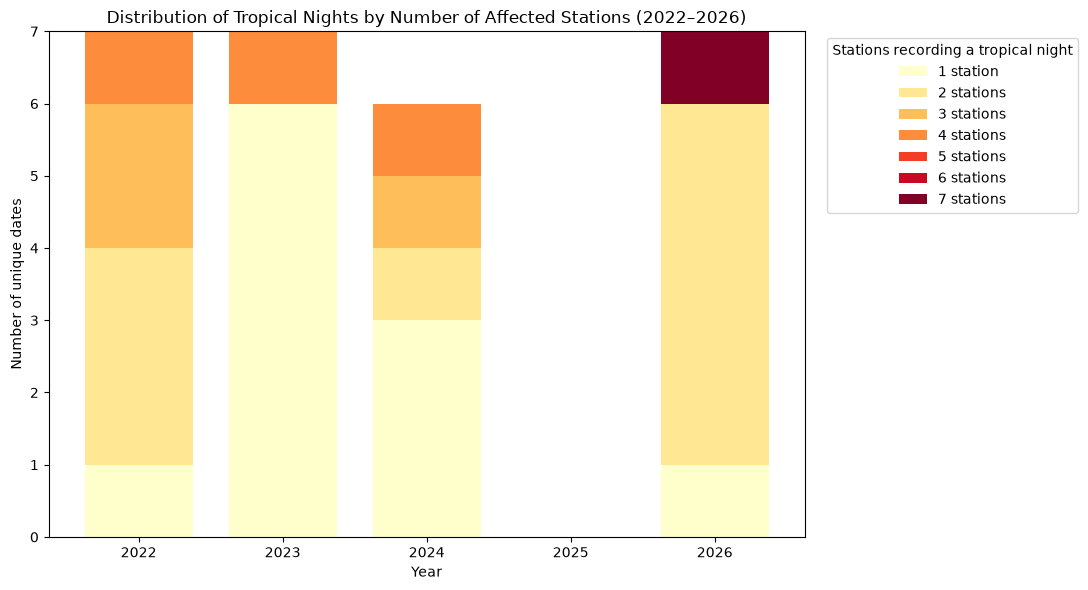

In [41]:
# Plot distribution of tropical-night dates by number of affected stations
ax = tropical_dates_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    colormap="YlOrRd",
    width=0.75
)

plt.title("Distribution of Tropical Nights by Number of Affected Stations (2022–2026)")
plt.xlabel("Year")
plt.ylabel("Number of unique dates")
plt.xticks(rotation=0)

plt.legend(
    title="Stations recording a tropical night",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Although 2022, 2023 and 2026 each recorded seven unique tropical-night dates, their spatial distribution differed considerably. In 2023, most occurrences were limited to individual stations, whereas in 2026, six of the seven dates involved multiple stations, including one date when all seven stations recorded a tropical night.